<a href="https://colab.research.google.com/github/Abdoulaye279/Financial-Engineering/blob/main/industry-allocation/02_allocation_backtest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 - Estimated risk vs 1/N: out-of-sample backtest, 1931-2018

Each month, weights from the previous 60 months only, holdings drift during the month, 10 bp per unit traded. Same test as DeMiguel, Garlappi and Uppal (2009): estimated allocations against the naive 1/N once estimation error is paid for. Takes ~2 min.

In [1]:
# colab: get the repo first
try:
    import google.colab
    !git clone -q https://github.com/Abdoulaye279/Financial-Engineering
    %cd Financial-Engineering/industry-allocation
except ImportError:
    pass

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from alloc import *
plt.style.use("quant.mplstyle")

R = load_french("data/ind30_m_vw_rets.csv") / 100           # 30 value-weighted US industry portfolios
ff = load_french("data/F-F_Research_Data_Factors_m.csv") / 100  # Mkt-RF, SMB, HML, RF
cap = load_french("data/ind30_m_size.csv") * load_french("data/ind30_m_nfirms.csv")   # industry market cap
n = R.shape[1]
print(R.shape, R.index[0], "->", R.index[-1])

(1110, 30) 1926-07 -> 2018-12


In [3]:
schemes = {
    "1/N": lambda past, t: np.full(n, 1 / n),
    "cap-weighted": lambda past, t: (cap.iloc[t - 1] / cap.iloc[t - 1].sum()).values,   # last month's caps, no look-ahead
    "min var, sample": lambda past, t: min_variance_weights(np.cov(past.T)),
    "min var, Ledoit-Wolf": lambda past, t: min_variance_weights(ledoit_wolf_cc(past)[0]),
    "risk parity, sample": lambda past, t: risk_parity_weights(np.cov(past.T)),
    "risk parity, Ledoit-Wolf": lambda past, t: risk_parity_weights(ledoit_wolf_cc(past)[0]),
    "min var long-short, sample": lambda past, t: min_variance_unconstrained(np.cov(past.T)),
    "min var long-short, Ledoit-Wolf": lambda past, t: min_variance_unconstrained(ledoit_wolf_cc(past)[0]),
}
res = {nm: backtest(R, fn, window=60, cost=0.001) for nm, fn in schemes.items()}
rf = ff["RF"].loc[res["1/N"][0].index]
rows = {}
for nm, (r, to) in res.items():
    s = stats(r, rf)
    b, t = ols_newey_west(r - rf, ff.loc[r.index, ["Mkt-RF", "SMB", "HML"]])
    rows[nm] = {**s, "turnover/yr": 12 * to.mean(), "FF3 alpha": 12 * b[0], "alpha t": t[0], "beta mkt": b[1]}
table = pd.DataFrame(rows).T
print(res["1/N"][0].index[0], "->", res["1/N"][0].index[-1])
table.style.format({"return": "{:.2%}", "vol": "{:.2%}", "sharpe": "{:.2f}", "max drawdown": "{:.1%}", "worst month": "{:.1%}",
                    "turnover/yr": "{:.2f}", "FF3 alpha": "{:.2%}", "alpha t": "{:.1f}", "beta mkt": "{:.2f}"})

1931-07 -> 2018-12


,return,vol,sharpe,max drawdown,worst month,turnover/yr,FF3 alpha,alpha t,beta mkt
1/N,12.38%,19.09%,0.47,-64.5%,-28.2%,0.33,0.26%,0.6,0.99
cap-weighted,11.35%,18.00%,0.45,-63.6%,-28.9%,0.43,0.05%,1.0,1.00
"min var, sample",10.70%,13.38%,0.55,-44.4%,-18.3%,1.34,2.69%,3.2,0.60
"min var, Ledoit-Wolf",10.41%,13.41%,0.53,-44.3%,-17.9%,1.20,2.38%,2.8,0.60
"risk parity, sample",12.31%,17.81%,0.50,-63.0%,-26.7%,0.39,0.88%,2.0,0.93
"risk parity, Ledoit-Wolf",12.28%,18.02%,0.50,-63.2%,-26.9%,0.36,0.74%,1.8,0.94
"min var long-short, sample",8.15%,15.32%,0.32,-52.4%,-17.6%,14.57,2.30%,1.5,0.36
"min var long-short, Ledoit-Wolf",8.94%,12.65%,0.45,-49.1%,-19.3%,3.94,3.51%,2.9,0.40


In [4]:
# 1/N (0.47) beats the cap-weighted market (0.45) and risk parity barely moves away from it (0.50): the
# industries have similar vols, so equal risk is close to equal money
# long-only min variance: best Sharpe (0.55), vol 13.4% vs 19.1%, max drawdown -44% vs -64%, market beta 0.60
# and a Fama-French alpha of 2.7%/yr (t = 3.2): the low-volatility anomaly
# Ledoit-Wolf doesn't help long-only (0.53 vs 0.55) but matters a lot with shorting allowed:
# sample 0.32 with 14.6 turnover/yr, Ledoit-Wolf 0.45 with 3.9
# -> Jagannathan and Ma (2003): the no-short constraint already acts as shrinkage, it blocks the extreme weights
#    that estimation errors create
ex = {nm: r - rf for nm, (r, to) in res.items()}
for a, b in [("min var, sample", "1/N"), ("min var, sample", "cap-weighted"), ("1/N", "cap-weighted"),
             ("risk parity, sample", "1/N"), ("min var, Ledoit-Wolf", "min var, sample"),
             ("min var long-short, Ledoit-Wolf", "min var long-short, sample")]:
    z, p = sharpe_test(ex[a], ex[b])
    print(f"{a:32s} vs {b:28s} z = {z:5.2f}  p = {p:.3f}")
# Jobson-Korkie / Memmel test: even over 87 years min variance vs 1/N is not significant (p = 0.23)
# risk parity vs 1/N is (p < 0.001) because the two are very correlated, but the gap is small (0.50 vs 0.47)
# the min variance alpha is significant while its Sharpe gain is not: same return with less market risk,
# and a Sharpe test has little power for that

min var, sample                  vs 1/N                          z =  1.19  p = 0.233
min var, sample                  vs cap-weighted                 z =  1.58  p = 0.114
1/N                              vs cap-weighted                 z =  1.27  p = 0.204
risk parity, sample              vs 1/N                          z =  3.49  p = 0.000
min var, Ledoit-Wolf             vs min var, sample              z = -1.12  p = 0.263
min var long-short, Ledoit-Wolf  vs min var long-short, sample   z =  1.82  p = 0.069


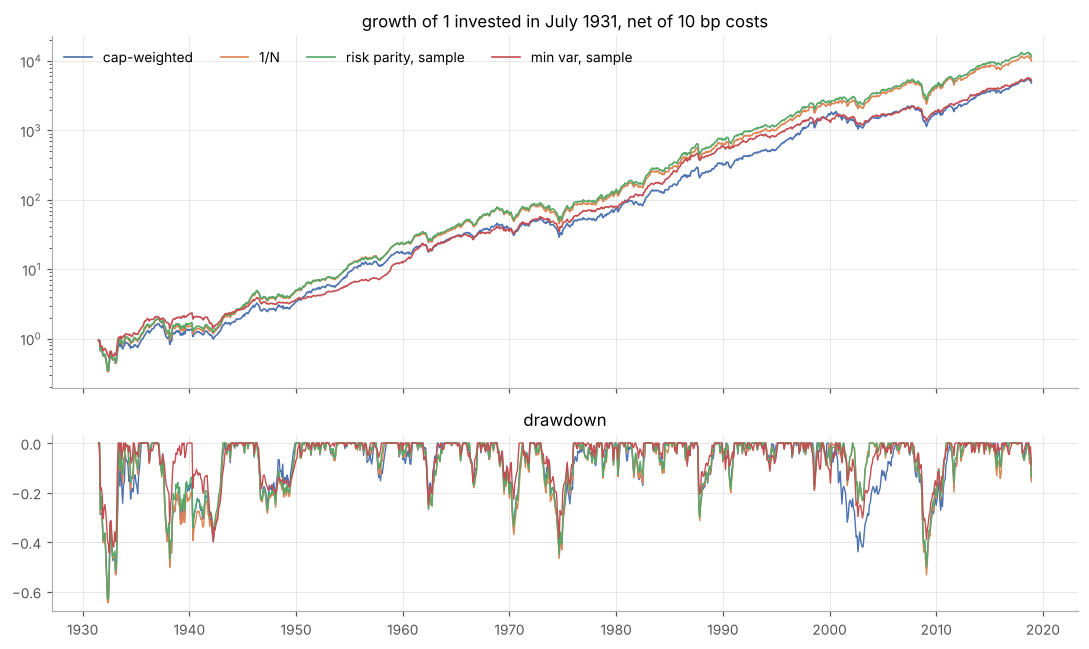

1937-03 -> 1938-03 {'cap-weighted': '-49.5%', '1/N': '-50.3%', 'risk parity, sample': '-46.7%', 'min var, sample': '-32.1%'}
1973-01 -> 1974-09 {'cap-weighted': '-46.0%', '1/N': '-46.7%', 'risk parity, sample': '-44.8%', 'min var, sample': '-38.4%'}
2000-09 -> 2002-09 {'cap-weighted': '-44.0%', '1/N': '-20.1%', 'risk parity, sample': '-17.4%', 'min var, sample': '-26.2%'}
2007-11 -> 2009-02 {'cap-weighted': '-50.1%', '1/N': '-53.3%', 'risk parity, sample': '-50.1%', 'min var, sample': '-39.0%'}


In [5]:
show = ["cap-weighted", "1/N", "risk parity, sample", "min var, sample"]
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for nm in show:
    w = (1 + res[nm][0]).cumprod()
    x = w.index.to_timestamp()
    ax[0].plot(x, w.values, label=nm)
    ax[1].plot(x, (w / w.cummax() - 1).values, lw=0.9)
ax[0].set_yscale("log"); ax[0].set_title("growth of 1 invested in July 1931, net of 10 bp costs"); ax[0].legend(ncol=4)
ax[1].set_title("drawdown")
plt.tight_layout(); plt.show()
for a, b in [("1937-03", "1938-03"), ("1973-01", "1974-09"), ("2000-09", "2002-09"), ("2007-11", "2009-02")]:
    print(a, "->", b, {nm: f"{(1 + res[nm][0].loc[a:b]).prod() - 1:.1%}" for nm in show})
# min variance loses the least in 1937-38, 1973-74 and 2008, but not in 2000-02: there 1/N (-20%) and risk parity
# (-17%) did better than min variance (-26%), and the cap-weighted market lost 44% because of its large tech weight

In [6]:
W = pd.DataFrame([min_variance_weights(np.cov(R.values[t - 60:t].T)) for t in range(60, len(R), 12)],
                 index=R.index[60::12], columns=R.columns)
top = W.mean().sort_values(ascending=False)
print("average min variance weight, top 8:", (100 * top.head(8)).round(1).to_dict())
print("industries with zero weight more than 80% of the time:", list(W.columns[(W < 1e-4).mean() > 0.8]))
print("number of industries held (weight > 1%): median", int((W > 0.01).sum(axis=1).median()))
# long-only min variance holds only a handful of industries (median 5): telecoms (32% on average) and utilities (20%),
# then tobacco and food
# a concentrated, defensive portfolio: low market beta, which is where its alpha comes from

average min variance weight, top 8: {'Telcm': 32.2, 'Util': 20.3, 'Smoke': 8.6, 'Food': 6.1, 'Oil': 4.4, 'Beer': 4.3, 'Clths': 4.2, 'Hshld': 3.1}
industries with zero weight more than 80% of the time: ['Games', 'Books', 'Chems', 'Txtls', 'Cnstr', 'Steel', 'FabPr', 'ElcEq', 'Autos', 'Carry', 'Coal', 'BusEq', 'Paper', 'Trans', 'Whlsl', 'Rtail', 'Meals', 'Fin', 'Other']
number of industries held (weight > 1%): median 5
